<a href="https://colab.research.google.com/github/LujainAyyash/DS483-Project/blob/main/Copy_of_NLP_Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Set Up and Load Dataset

In [1]:
# for data load, tabulation, and visualization
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# for data preprocessing
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import RegexpTokenizer
from nltk.stem.porter import PorterStemmer
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:
upload = files.upload()
df = pd.read_csv('SMSSpamCollection', header = None, sep = '\t')

Saving SMSSpamCollection to SMSSpamCollection


In [3]:
df

,0,1
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [4]:
df.shape

(5572, 2)

In [5]:
df.columns = ['class', 'message']
df.head()

,class,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [6]:
df.isnull().sum()

,0
class,0
message,0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   class    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [8]:
df['class'].value_counts()

,count
class,
ham,4825
spam,747


# Explore Data

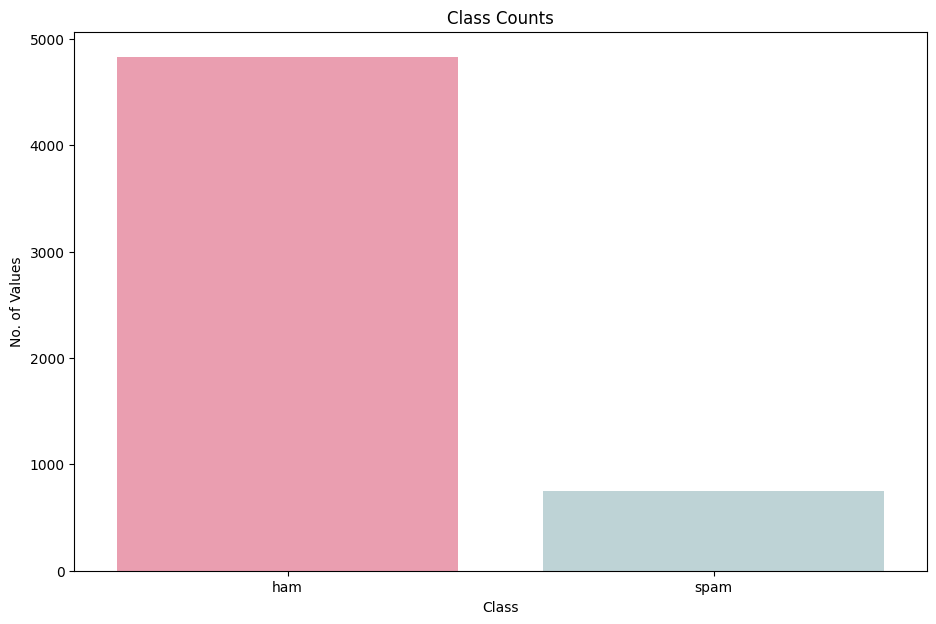

In [9]:
plt.figure(figsize=(11,7))
chrt = sns.countplot(x= df["class"], palette= ["#F791A9", "#BAD6DA"])
chrt.set_title("Class Counts")
chrt.set_xlabel("Class")
chrt.set_ylabel("No. of Values")
plt.show()

This indicates that the messages that are legit are more than the spam messages in the dataset.

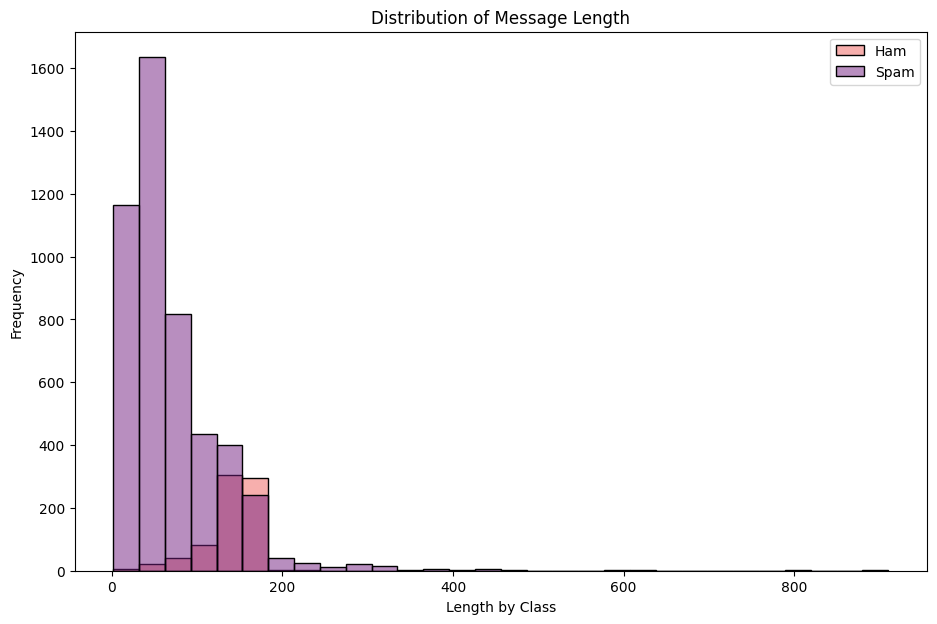

In [10]:
df['msg_len'] = df['message'].apply(len)
plt.figure(figsize=(11,7))
sns.histplot(data=df, x='msg_len', hue='class', bins=30, palette='magma')
plt.title('Distribution of Message Length')
plt.xlabel('Length by Class')
plt.ylabel('Frequency')
plt.legend(['Ham', 'Spam'])
plt.show()

The chart shows that ham messages are longer by length than the spam messages.

In [12]:
df['wc_map'] = df['class'].map({'ham': 0, 'spam': 1})

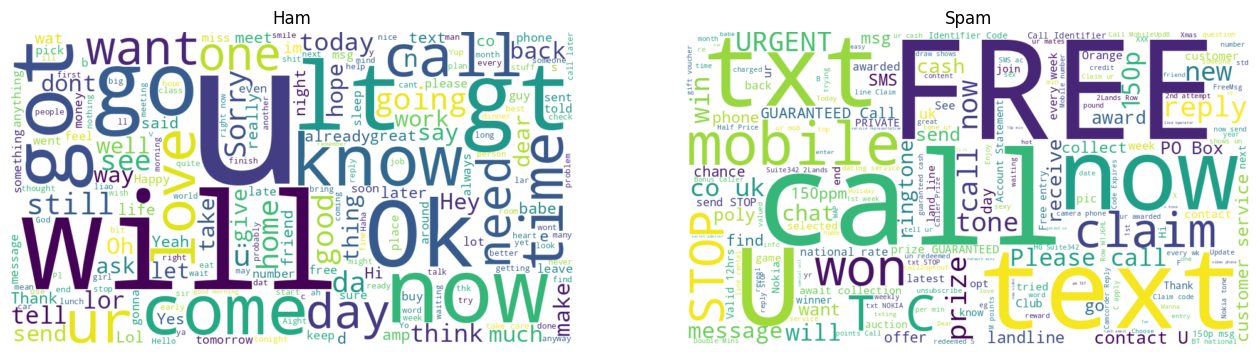

In [13]:
hamW = ' '.join(df[df['wc_map'] == 0]['message'])
wcHam = WordCloud(width=900, height=500, background_color='white').generate(hamW)
spamW = ' '.join(df[df['wc_map'] == 1]['message'])
wcSpam = WordCloud(width=900, height=500, background_color='white').generate(spamW)

plt.figure(figsize=(16,8))

plt.subplot(1,2,1)
plt.imshow(wcHam, interpolation='bilinear')
plt.title('Ham')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(wcSpam, interpolation='bilinear')
plt.title('Spam')
plt.axis('off')

plt.show()

It is apparent from the word clouds that the words "u", "will", "ok", "come", etc. are commonly found in ham messages while the words "call", "FREE", "now", "won", etc. are commonly found in spam messages.